In [1]:
from google.colab import files
uploaded = files.upload()

Saving holidays_events.csv to holidays_events.csv
Saving oil.csv to oil.csv
Saving sample_submission.csv to sample_submission.csv
Saving stores.csv to stores.csv
Saving test.csv to test.csv
Saving train.csv to train.csv
Saving transactions.csv to transactions.csv


In [319]:
import pandas as pd

df_holidays_events = pd.read_csv('holidays_events.csv')
df_oil = pd.read_csv('oil.csv')
df_sample_submission = pd.read_csv('sample_submission.csv')
df_stores = pd.read_csv('stores.csv')
df_test = pd.read_csv('test.csv')
df_train = pd.read_csv('train.csv')
df_transactions = pd.read_csv('transactions.csv')

In [320]:
#df_oil = pd.read_csv('oil.csv')

In [321]:
df_all = [df_holidays_events, df_oil, df_sample_submission, df_stores, df_test, df_train, df_transactions]
df_names = ['df_holidays_events', 'df_oil', 'df_sample_submission', 'df_stores', 'df_test', 'df_train', 'df_transactions']

In [322]:
for i, (name, df) in enumerate(zip(df_names, df_all), start=1):
  print(f"{name}")
  print("=" * 20)
  print(df.columns)
  print("_" * 50)


df_holidays_events
Index(['date', 'type', 'locale', 'locale_name', 'description', 'transferred'], dtype='object')
__________________________________________________
df_oil
Index(['date', 'dcoilwtico'], dtype='object')
__________________________________________________
df_sample_submission
Index(['id', 'sales'], dtype='object')
__________________________________________________
df_stores
Index(['store_nbr', 'city', 'state', 'type', 'cluster'], dtype='object')
__________________________________________________
df_test
Index(['id', 'date', 'store_nbr', 'family', 'onpromotion'], dtype='object')
__________________________________________________
df_train
Index(['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion'], dtype='object')
__________________________________________________
df_transactions
Index(['date', 'store_nbr', 'transactions'], dtype='object')
__________________________________________________


## EDA of **'df_holidays_events'**

In [323]:
df_holidays_events.shape

(350, 6)

In [324]:
df_holidays_events.head(5)

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [325]:
df_holidays_events.tail(5)

,date,type,locale,locale_name,description,transferred
345,2017-12-22,Additional,National,Ecuador,Navidad-3,False
346,2017-12-23,Additional,National,Ecuador,Navidad-2,False
347,2017-12-24,Additional,National,Ecuador,Navidad-1,False
348,2017-12-25,Holiday,National,Ecuador,Navidad,False
349,2017-12-26,Additional,National,Ecuador,Navidad+1,False


In [326]:
df_holidays_events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   date         350 non-null    object
 1   type         350 non-null    object
 2   locale       350 non-null    object
 3   locale_name  350 non-null    object
 4   description  350 non-null    object
 5   transferred  350 non-null    bool  
dtypes: bool(1), object(5)
memory usage: 14.1+ KB


In [327]:
# Checking null values
df_holidays_events.isnull().sum().sum()

np.int64(0)

In [328]:
# Checking duplicate rows
df_holidays_events.duplicated().sum()

np.int64(0)

In [329]:
# To check Unexpected/typo values in below categorical cols

cat_col = ['type', 'locale', 'locale_name', 'transferred']

for col in cat_col:
  print(df_holidays_events[col].value_counts(dropna=False))
  print("=" * 50)

type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64
locale
National    174
Local       152
Regional     24
Name: count, dtype: int64
locale_name
Ecuador                           174
Quito                              13
Guaranda                           12
Riobamba                           12
Latacunga                          12
Ambato                             12
Guayaquil                          11
Cuenca                              7
Ibarra                              7
Imbabura                            6
Cotopaxi                            6
Libertad                            6
Manta                               6
Puyo                                6
El Carmen                           6
Machala                             6
Cayambe                             6
Esmeraldas                          6
Santo Domingo                       6
Quevedo                             6
Santa El

In [330]:
# Change datatype of to 'datetime'
df_holidays_events['date'] = pd.to_datetime(df_holidays_events['date'])

In [331]:
print(df_holidays_events['date'].dtypes)

datetime64[ns]


In [332]:
# Check for reasonable value
df_holidays_events.describe()

,date
count,350
mean,2015-04-24 00:45:15.428571392
min,2012-03-02 00:00:00
25%,2013-12-23 06:00:00
50%,2015-06-08 00:00:00
75%,2016-07-03 00:00:00
max,2017-12-26 00:00:00


In [333]:
df_holidays_events

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
...,...,...,...,...,...,...
345,2017-12-22,Additional,National,Ecuador,Navidad-3,False
346,2017-12-23,Additional,National,Ecuador,Navidad-2,False
347,2017-12-24,Additional,National,Ecuador,Navidad-1,False
348,2017-12-25,Holiday,National,Ecuador,Navidad,False


## EDA of **'df_oil'**

In [334]:
df_oil.shape

(1218, 2)

In [335]:
df_oil.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        1218 non-null   object 
 1   dcoilwtico  1175 non-null   float64
dtypes: float64(1), object(1)
memory usage: 19.2+ KB


In [336]:
# Checking duplicate rows
df_oil.duplicated().sum()

np.int64(0)

In [337]:
# Checking null value check
df_oil.isnull().sum()

,0
date,0
dcoilwtico,43


In [338]:
df_oil.head(5)

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [339]:
df_oil[df_oil['dcoilwtico'].isna()]['date']

,date
0,2013-01-01
14,2013-01-21
34,2013-02-18
63,2013-03-29
104,2013-05-27
132,2013-07-04
174,2013-09-02
237,2013-11-28
256,2013-12-25
261,2014-01-01


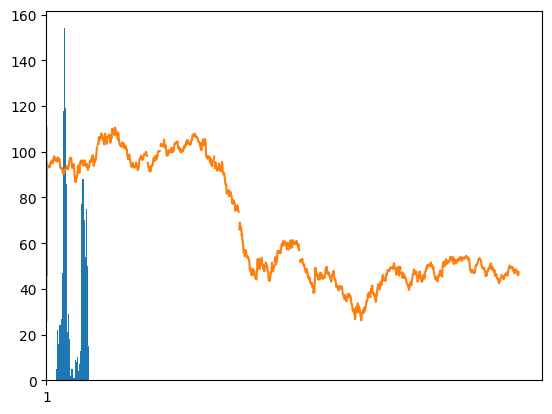

In [340]:
import matplotlib.pyplot as plt
# Distribution
plt.hist(df_oil['dcoilwtico'].dropna(), bins=30)

# Outliers
plt.boxplot(df_oil['dcoilwtico'].dropna())

# Trend over Time
plt.plot(df_oil['date'], df_oil['dcoilwtico'])

plt.show()

In [341]:
# There are 43 null values.
# we are dealing with timeseries data of oil price so we can fill null value by ffill or bfill method.

In [342]:
df_oil.head(10)

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20
5,2013-01-08,93.21
6,2013-01-09,93.08
7,2013-01-10,93.81
8,2013-01-11,93.60
9,2013-01-14,94.27


In [343]:
df_oil['dcoilwtico'].head()

,dcoilwtico
0,NaN
1,93.14
2,92.97
3,93.12
4,93.20


In [344]:
df_oil['dcoilwtico'].tail(10)

,dcoilwtico
1208,48.59
1209,47.39
1210,47.65
1211,48.45
1212,47.24
1213,47.65
1214,46.40
1215,46.46
1216,45.96
1217,47.26


In [345]:
# 1st value is null so we are using firstly bfill then ffill
df_oil['dcoilwtico'] = df_oil['dcoilwtico'].bfill().ffill()

In [346]:
df_oil['dcoilwtico'].isnull().sum().sum()

np.int64(0)

In [347]:
df_oil.head()

,date,dcoilwtico
0,2013-01-01,93.14
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [348]:
df_oil.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        1218 non-null   object 
 1   dcoilwtico  1218 non-null   float64
dtypes: float64(1), object(1)
memory usage: 19.2+ KB


In [349]:
# Change datatype of to 'datetime'
df_oil['date'] = pd.to_datetime(df_oil['date'])

In [350]:
df_oil.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1218 non-null   datetime64[ns]
 1   dcoilwtico  1218 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.2 KB


In [351]:
# Check for reasonable value
df_oil.describe()

,date,dcoilwtico
count,1218,1218.000000
mean,2015-05-02 12:00:00,67.673325
min,2013-01-01 00:00:00,26.190000
25%,2014-03-03 06:00:00,46.422500
50%,2015-05-02 12:00:00,53.185000
75%,2016-06-30 18:00:00,95.595000
max,2017-08-31 00:00:00,110.620000
std,NaN,25.637345


## EDA of **'df_sample_submission'**

In [352]:
# sample_submission.csv was provided only as a submission template.
# It contains the required output columns (id and sales) and was used to format final predictions for submission.
# Since it does not contain business data or predictive features, no detailed EDA was performed on it."

## EDA of **'df_stores'**




In [353]:
df_stores.head(5)

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [354]:
df_stores.shape

(54, 5)

In [355]:
df_stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   store_nbr  54 non-null     int64 
 1   city       54 non-null     object
 2   state      54 non-null     object
 3   type       54 non-null     object
 4   cluster    54 non-null     int64 
dtypes: int64(2), object(3)
memory usage: 2.2+ KB


In [356]:
# Checking null value check
df_stores.isnull().sum().sum()

np.int64(0)

In [357]:
# Check duplicate value
df_stores.duplicated().sum()

np.int64(0)

In [358]:
# Check duplicate IDs
df_stores['store_nbr'].duplicated().sum()

np.int64(0)

In [359]:
# To check Unexpected/typo values in categorical col
df_stores.columns


Index(['store_nbr', 'city', 'state', 'type', 'cluster'], dtype='object')

In [360]:
# To check Unexpected/typo values in below categorical cols
cat_col2 = ['city', 'state', 'type', 'cluster']

for col in cat_col2:
  print(df_stores[col].value_counts(dropna=False))
  print("=" * 50)

city
Quito            18
Guayaquil         8
Cuenca            3
Santo Domingo     3
Latacunga         2
Machala           2
Manta             2
Ambato            2
Cayambe           1
Riobamba          1
Ibarra            1
Salinas           1
Puyo              1
Guaranda          1
Quevedo           1
Babahoyo          1
Daule             1
Playas            1
Loja              1
Libertad          1
Esmeraldas        1
El Carmen         1
Name: count, dtype: int64
state
Pichincha                         19
Guayas                            11
Azuay                              3
Santo Domingo de los Tsachilas     3
Manabi                             3
Los Rios                           2
Cotopaxi                           2
Tungurahua                         2
El Oro                             2
Bolivar                            1
Imbabura                           1
Chimborazo                         1
Pastaza                            1
Santa Elena                        1
Loja 

In [361]:
# Check for reasonable value
df_stores.describe()

,store_nbr,cluster
count,54.000000,54.000000
mean,27.500000,8.481481
std,15.732133,4.693395
min,1.000000,1.000000
25%,14.250000,4.000000
50%,27.500000,8.500000
75%,40.750000,13.000000
max,54.000000,17.000000


## EDA of **'df_test'**




In [362]:
df_test.head()

,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


In [363]:
df_test.shape

(28512, 5)

In [364]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28512 entries, 0 to 28511
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           28512 non-null  int64 
 1   date         28512 non-null  object
 2   store_nbr    28512 non-null  int64 
 3   family       28512 non-null  object
 4   onpromotion  28512 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 1.1+ MB


In [365]:
# Checking duplicate ID rows
df_test['id'].duplicated().sum()


np.int64(0)

In [366]:
# Checking duplicate rows
df_test.duplicated().sum()


np.int64(0)

In [367]:
# Checking null value check
df_test.isnull().sum().sum()

np.int64(0)

In [368]:
# Change datatype of to 'datetime'
df_test['date'] = pd.to_datetime(df_test['date'])

In [369]:
print(df_test['date'].dtype)

datetime64[ns]


In [370]:
test_col = df_test.columns.tolist()
test_col = test_col[1:-1]
test_col

['date', 'store_nbr', 'family']

In [371]:
# To check Unexpected/typo values in categorical col

for col in test_col:
  print(df_test[col].value_counts(dropna=False))
  print("=" * 50)

date
2017-08-16    1782
2017-08-17    1782
2017-08-18    1782
2017-08-19    1782
2017-08-20    1782
2017-08-21    1782
2017-08-22    1782
2017-08-23    1782
2017-08-24    1782
2017-08-25    1782
2017-08-26    1782
2017-08-27    1782
2017-08-28    1782
2017-08-29    1782
2017-08-30    1782
2017-08-31    1782
Name: count, dtype: int64
store_nbr
1     528
10    528
11    528
12    528
13    528
14    528
15    528
16    528
17    528
18    528
19    528
2     528
20    528
21    528
22    528
23    528
24    528
25    528
26    528
27    528
28    528
29    528
3     528
30    528
31    528
32    528
33    528
34    528
35    528
36    528
37    528
38    528
39    528
4     528
40    528
41    528
42    528
43    528
44    528
45    528
46    528
47    528
48    528
49    528
5     528
50    528
51    528
52    528
53    528
54    528
6     528
7     528
8     528
9     528
Name: count, dtype: int64
family
AUTOMOTIVE                    864
BABY CARE                     864
BEAUTY        

In [372]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28512 entries, 0 to 28511
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           28512 non-null  int64         
 1   date         28512 non-null  datetime64[ns]
 2   store_nbr    28512 non-null  int64         
 3   family       28512 non-null  object        
 4   onpromotion  28512 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(1)
memory usage: 1.1+ MB


In [373]:
df_test.head()

,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


In [374]:
# Check for reasonable value
df_test.describe()

,id,date,store_nbr,onpromotion
count,2.851200e+04,28512,28512.000000,28512.000000
mean,3.015144e+06,2017-08-23 12:00:00,27.500000,6.965383
min,3.000888e+06,2017-08-16 00:00:00,1.000000,0.000000
25%,3.008016e+06,2017-08-19 18:00:00,14.000000,0.000000
50%,3.015144e+06,2017-08-23 12:00:00,27.500000,0.000000
75%,3.022271e+06,2017-08-27 06:00:00,41.000000,6.000000
max,3.029399e+06,2017-08-31 00:00:00,54.000000,646.000000
std,8.230850e+03,NaN,15.586057,20.683952


## EDA of **'df_transactions'**

In [375]:
df_transactions.head(5)

,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


In [376]:
df_transactions.shape

(83488, 3)

In [377]:
df_transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83488 entries, 0 to 83487
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          83488 non-null  object
 1   store_nbr     83488 non-null  int64 
 2   transactions  83488 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 1.9+ MB


In [378]:
# Checking duplicate rows
df_transactions.duplicated().sum()

np.int64(0)

In [379]:
# Checking null value check
df_transactions.isnull().sum().sum()

np.int64(0)

In [380]:
# Change datatype of to 'datetime'
df_transactions['date'] = pd.to_datetime(df_transactions['date'])

In [381]:
print(df_transactions['date'].dtype)

datetime64[ns]


In [382]:
# Check for reasonable value
df_transactions.describe()

,date,store_nbr,transactions
count,83488,83488.000000,83488.000000
mean,2015-05-20 16:07:40.866232064,26.939237,1694.602158
min,2013-01-01 00:00:00,1.000000,5.000000
25%,2014-03-27 00:00:00,13.000000,1046.000000
50%,2015-06-08 00:00:00,27.000000,1393.000000
75%,2016-07-14 06:00:00,40.000000,2079.000000
max,2017-08-15 00:00:00,54.000000,8359.000000
std,NaN,15.608204,963.286644


## *** EDA of **'df_train'** ***

In [383]:
df_train.head(5)

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [384]:
df_train.shape

(3000888, 6)

In [385]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB


In [386]:
# Checking null value check
df_train.isnull().sum().sum()

np.int64(0)

In [387]:
# Checking duplicate rows
df_train.duplicated().sum()

np.int64(0)

In [388]:
# Checking duplicate ID rows
df_train['id'].duplicated().sum()

np.int64(0)

In [389]:
# Change datatype of to 'datetime'
df_train['date'] = pd.to_datetime(df_train['date'])

In [390]:
print(df_train['date'].dtype)

datetime64[ns]


In [391]:
df_train.columns

Index(['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion'], dtype='object')

In [392]:
# To check Unexpected/typo values in categorical col

train_col = ['store_nbr', 'family']

for col in train_col:
  print("=" * 40)
  print(df_train[col].value_counts(dropna=False))

store_nbr
1     55572
10    55572
11    55572
12    55572
13    55572
14    55572
15    55572
16    55572
17    55572
18    55572
19    55572
2     55572
20    55572
21    55572
22    55572
23    55572
24    55572
25    55572
26    55572
27    55572
28    55572
29    55572
3     55572
30    55572
31    55572
32    55572
33    55572
34    55572
35    55572
36    55572
37    55572
38    55572
39    55572
4     55572
40    55572
41    55572
42    55572
43    55572
44    55572
45    55572
46    55572
47    55572
48    55572
49    55572
5     55572
50    55572
51    55572
52    55572
53    55572
54    55572
6     55572
7     55572
8     55572
9     55572
Name: count, dtype: int64
family
AUTOMOTIVE                    90936
BABY CARE                     90936
BEAUTY                        90936
BEVERAGES                     90936
BOOKS                         90936
BREAD/BAKERY                  90936
CELEBRATION                   90936
CLEANING                      90936
DAIRY                

In [393]:
# Check for reasonable value
df_train.describe()


,id,date,store_nbr,sales,onpromotion
count,3.000888e+06,3000888,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2015-04-24 08:27:04.703088384,2.750000e+01,3.577757e+02,2.602770e+00
min,0.000000e+00,2013-01-01 00:00:00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,2014-02-26 18:00:00,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2015-04-24 12:00:00,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,2016-06-19 06:00:00,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,2017-08-15 00:00:00,5.400000e+01,1.247170e+05,7.410000e+02
std,8.662819e+05,NaN,1.558579e+01,1.101998e+03,1.221888e+01


## *** EDA done of all dataset ***

In [395]:
df_train.head(5)

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [396]:
df_train.shape

(3000888, 6)

In [397]:
df_stores.shape

(54, 5)

In [398]:
df_stores.head(3)

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8


In [408]:
#del df_merged

##  *** Merging of datasets with **df_train** ****

In [409]:
df_merged = df_train.merge(df_stores, on='store_nbr', how='left')

In [410]:
df_merged.head(5)

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13


In [411]:
df_merged.isnull().sum().sum()

np.int64(0)

In [412]:
df_oil.columns

Index(['date', 'dcoilwtico'], dtype='object')

In [413]:
# Merging with 'df_oil'

df_merged = df_merged.merge(df_oil, on='date', how='left')

In [414]:
df_merged.head(5)

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,dcoilwtico
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,93.14
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,93.14
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,93.14
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,93.14
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,93.14


In [415]:
df_merged.tail(5)

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,dcoilwtico
3000883,3000883,2017-08-15,9,POULTRY,438.133,0,Quito,Pichincha,B,6,47.57
3000884,3000884,2017-08-15,9,PREPARED FOODS,154.553,1,Quito,Pichincha,B,6,47.57
3000885,3000885,2017-08-15,9,PRODUCE,2419.729,148,Quito,Pichincha,B,6,47.57
3000886,3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,8,Quito,Pichincha,B,6,47.57
3000887,3000887,2017-08-15,9,SEAFOOD,16.000,0,Quito,Pichincha,B,6,47.57


In [419]:
df_merged.isnull().sum()

,0
id,0
date,0
store_nbr,0
family,0
sales,0
onpromotion,0
city,0
state,0
type,0
cluster,0


In [417]:
df_merged.shape

(3000888, 11)

In [418]:
# Found 857142 null values in col 'dcoilwtico'

In [420]:
df_oil.shape

(1218, 2)

In [421]:
df_oil['date'].nunique()

1218

In [422]:
df_train['date'].nunique()

1684

In [423]:
print(df_merged['date'].dtypes)

datetime64[ns]


In [424]:
print(df_oil['date'].dtypes)

datetime64[ns]


In [425]:
df_oil['dcoilwtico'].isna().sum()

np.int64(0)

In [426]:
df_merged.loc[
    df_merged['dcoilwtico'].isna(),
    'date'
].nunique()

481

In [428]:
unmatched_dates = ~df_train['date'].isin(df_oil['date'])
print(df_train.loc[unmatched_dates, 'date'].nunique())

481


In [429]:
print(df_train['date'].min(), df_train['date'].max())
print(df_oil['date'].min(), df_oil['date'].max())

2013-01-01 00:00:00 2017-08-15 00:00:00
2013-01-01 00:00:00 2017-08-31 00:00:00


In [430]:
print(df_train['date'].nunique())
print(df_oil['date'].nunique())

1684
1218


In [431]:
print(len(missing_values))

481


In [432]:
df_oil['dcoilwtico'].isnull().sum()

np.int64(0)

In [433]:
print(df_train['date'].min(), df_train['date'].max())
print(df_oil['date'].min(), df_oil['date'].max())

2013-01-01 00:00:00 2017-08-15 00:00:00
2013-01-01 00:00:00 2017-08-31 00:00:00


In [440]:
# Checking days of top 20 missing dates
missing_dates = sorted(
    list(set(df_train['date']) - set(df_oil['date']))
)

for date in missing_dates[:20]:
    print(date.date(), "-", date.day_name())

2013-01-05 - Saturday
2013-01-06 - Sunday
2013-01-12 - Saturday
2013-01-13 - Sunday
2013-01-19 - Saturday
2013-01-20 - Sunday
2013-01-26 - Saturday
2013-01-27 - Sunday
2013-02-02 - Saturday
2013-02-03 - Sunday
2013-02-09 - Saturday
2013-02-10 - Sunday
2013-02-16 - Saturday
2013-02-17 - Sunday
2013-02-23 - Saturday
2013-02-24 - Sunday
2013-03-02 - Saturday
2013-03-03 - Sunday
2013-03-09 - Saturday
2013-03-10 - Sunday


In [441]:
df_oil.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1218 non-null   datetime64[ns]
 1   dcoilwtico  1218 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.2 KB


In [ ]:
# I have matched these dates as all are almost Saturday and Sunday hence are empty in df_oil dataset.
# Firstly, we convert the 'df_oil' on daily frequency ('D')

In [442]:
df_oil = (df_oil.set_index('date').asfreq('D'))

In [443]:
df_oil.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1704 entries, 2013-01-01 to 2017-08-31
Freq: D
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dcoilwtico  1218 non-null   float64
dtypes: float64(1)
memory usage: 26.6 KB


In [444]:
df_oil.head(3)

,dcoilwtico
date,
2013-01-01,93.14
2013-01-02,93.14
2013-01-03,92.97


In [445]:
# bow filling them by bfill and ffill method
df_oil['dcoilwtico'] = (df_oil['dcoilwtico'].ffill().bfill())

In [447]:
df_oil.head(5)

,dcoilwtico
date,
2013-01-01,93.14
2013-01-02,93.14
2013-01-03,92.97
2013-01-04,93.12
2013-01-05,93.12


In [448]:
# reset the index
df_oil = df_oil.reset_index()

In [449]:
df_oil.head(5)

,date,dcoilwtico
0,2013-01-01,93.14
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-05,93.12


In [450]:
print(df_oil['date'].nunique())
print(df_oil['dcoilwtico'].isna().sum())

1704
0


In [451]:
del df_mergded
# Again merge both datasets

In [452]:
df_merged = df_train.merge(df_stores, on='store_nbr', how='left')

In [454]:
df_merged.isnull().sum().sum()

np.int64(0)

In [455]:
df_merged = df_merged.merge(df_oil, on='date', how='left')

In [456]:
df_merged.isnull().sum().sum()

np.int64(0)

In [458]:
# Merging df_holidays_events with df_merged dataset
df_holidays_events['date'].duplicated().sum()

np.int64(38)

In [459]:
df_holidays_events.shape

(350, 6)

In [462]:
df_holidays_events['date'].nunique()

312

In [463]:
# Checking dulicate rows:
df_holidays_events['date'].value_counts().head(10)

,count
date,
2014-06-25,4
2016-06-25,3
2012-06-25,3
2015-06-25,3
2017-06-25,3
2013-06-25,3
2015-12-22,2
2012-12-22,2
2012-12-24,2


In [464]:
df_holidays_events[
    df_holidays_events['date'] == '2014-06-25'
]

,date,type,locale,locale_name,description,transferred
110,2014-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
111,2014-06-25,Holiday,Local,Machala,Fundacion de Machala,False
112,2014-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False
113,2014-06-25,Event,National,Ecuador,Mundial de futbol Brasil: Ecuador-Francia,False


In [467]:
# create flag col for df_holidays_events
holiday_flag = (df_holidays_events[['date']].drop_duplicates())

holiday_flag['is_holiday'] = 1

In [468]:
df_merged = df_merged.merge(holiday_flag,on='date',how='left')

In [469]:
df_merged['is_holiday'] = (df_merged['is_holiday'].fillna(0).astype(int))

In [470]:
df_merged.head(5)

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,dcoilwtico,is_holiday
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,93.14,1
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,93.14,1
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,93.14,1
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,93.14,1
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,93.14,1


In [471]:
df_merged.shape

(3000888, 12)

In [472]:
df_merged.isnull().sum().sum()

np.int64(0)

In [473]:
# Mergeing 'df_transactions' in 'df_merged'
df_transactions.shape

(83488, 3)

In [474]:
df_transactions.columns

Index(['date', 'store_nbr', 'transactions'], dtype='object')

In [481]:
df_transactions.head(5)

,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


In [475]:
df_transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83488 entries, 0 to 83487
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          83488 non-null  datetime64[ns]
 1   store_nbr     83488 non-null  int64         
 2   transactions  83488 non-null  int64         
dtypes: datetime64[ns](1), int64(2)
memory usage: 1.9 MB


In [483]:
# Mergeing 'df_transactions' in 'df_merged'
df_merged = df_merged.merge(df_transactions, on=['date', 'store_nbr'], how='left')

In [485]:
df_merged.head(5)

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,dcoilwtico,is_holiday,transactions
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN


In [486]:
df_merged.isnull().sum().sum()

np.int64(245784)

In [487]:
null_pct = (df_merged['transactions'].isna().sum() / len(df_merged)) * 100

print(f"{null_pct:.2f}%")

8.19%


In [488]:
print(df_transactions['date'].nunique())
print(df_train['date'].nunique())

1682
1684


In [489]:
print(df_transactions['store_nbr'].nunique())
print(df_train['store_nbr'].nunique())

54
54


In [490]:
# difference found in date
missing_dates = sorted(
    set(df_train['date']) - set(df_transactions['date'])
)

print(missing_dates)

[Timestamp('2016-01-01 00:00:00'), Timestamp('2016-01-03 00:00:00')]


In [491]:
df_transactions.shape

(83488, 3)

In [492]:
df_transactions['transactions'].isna().sum()

np.int64(0)

In [493]:
df_transactions[['date', 'store_nbr']].drop_duplicates().shape

(83488, 2)

In [494]:
df_transactions.isnull().sum()

,0
date,0
store_nbr,0
transactions,0


In [495]:
store_nbr_mis = (set(df_merged['store_nbr']) - set(df_transactions['store_nbr']))
print(store_nbr_mis)

set()


In [496]:
date_mis = (set(df_merged['date']) - set(df_transactions['date']))
print(date_mis)

{Timestamp('2016-01-01 00:00:00'), Timestamp('2016-01-03 00:00:00')}


In [498]:
df_merged[
    (df_merged['date'].isin([
        pd.Timestamp('2016-01-01'),
        pd.Timestamp('2016-01-03')
    ]))
    &
    (df_merged['transactions'].isna())
]

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,dcoilwtico,is_holiday,transactions
1945944,1945944,2016-01-01,1,AUTOMOTIVE,0.000,0,Quito,Pichincha,D,13,36.81,1,NaN
1945945,1945945,2016-01-01,1,BABY CARE,0.000,0,Quito,Pichincha,D,13,36.81,1,NaN
1945946,1945946,2016-01-01,1,BEAUTY,0.000,0,Quito,Pichincha,D,13,36.81,1,NaN
1945947,1945947,2016-01-01,1,BEVERAGES,0.000,0,Quito,Pichincha,D,13,36.81,1,NaN
1945948,1945948,2016-01-01,1,BOOKS,0.000,0,Quito,Pichincha,D,13,36.81,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1951285,1951285,2016-01-03,9,POULTRY,748.386,0,Quito,Pichincha,B,6,36.81,0,NaN
1951286,1951286,2016-01-03,9,PREPARED FOODS,143.022,0,Quito,Pichincha,B,6,36.81,0,NaN
1951287,1951287,2016-01-03,9,PRODUCE,3015.563,0,Quito,Pichincha,B,6,36.81,0,NaN
1951288,1951288,2016-01-03,9,SCHOOL AND OFFICE SUPPLIES,13.000,0,Quito,Pichincha,B,6,36.81,0,NaN


In [499]:
df_merged[(df_merged['transactions'].isna())]

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,dcoilwtico,is_holiday,transactions
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2790409,2790409,2017-04-19,52,POULTRY,0.0,0,Manta,Manabi,A,11,50.49,0,NaN
2790410,2790410,2017-04-19,52,PREPARED FOODS,0.0,0,Manta,Manabi,A,11,50.49,0,NaN
2790411,2790411,2017-04-19,52,PRODUCE,0.0,0,Manta,Manabi,A,11,50.49,0,NaN
2790412,2790412,2017-04-19,52,SCHOOL AND OFFICE SUPPLIES,0.0,0,Manta,Manabi,A,11,50.49,0,NaN


In [500]:
df_merged.loc[
    df_merged['transactions'].isna(),
    'date'
].nunique()

1566

In [501]:
sorted(
    df_merged.loc[
        df_merged['transactions'].isna(),
        'date'
    ].unique()
)[:20]

[Timestamp('2013-01-01 00:00:00'),
 Timestamp('2013-01-02 00:00:00'),
 Timestamp('2013-01-03 00:00:00'),
 Timestamp('2013-01-04 00:00:00'),
 Timestamp('2013-01-05 00:00:00'),
 Timestamp('2013-01-06 00:00:00'),
 Timestamp('2013-01-07 00:00:00'),
 Timestamp('2013-01-08 00:00:00'),
 Timestamp('2013-01-09 00:00:00'),
 Timestamp('2013-01-10 00:00:00'),
 Timestamp('2013-01-11 00:00:00'),
 Timestamp('2013-01-12 00:00:00'),
 Timestamp('2013-01-13 00:00:00'),
 Timestamp('2013-01-14 00:00:00'),
 Timestamp('2013-01-15 00:00:00'),
 Timestamp('2013-01-16 00:00:00'),
 Timestamp('2013-01-17 00:00:00'),
 Timestamp('2013-01-18 00:00:00'),
 Timestamp('2013-01-19 00:00:00'),
 Timestamp('2013-01-20 00:00:00')]

In [502]:
df_merged.loc[
    df_merged['transactions'].isna(),
    ['date', 'store_nbr']
].drop_duplicates().shape

(7448, 2)

In [503]:
df_merged.loc[
    df_merged['transactions'].isna(),
    'store_nbr'
].value_counts().head()

,count
store_nbr,
52,51678
22,33429
42,31812
21,30888
29,26730


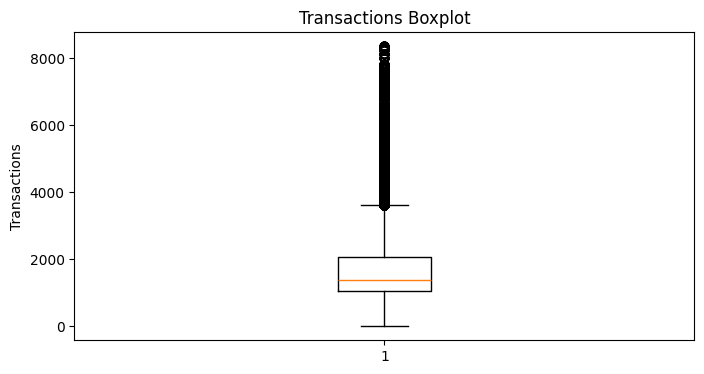

In [505]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.boxplot(df_merged['transactions'].dropna())
plt.title('Transactions Boxplot')
plt.ylabel('Transactions')
plt.show()

In [506]:
# median of transactions groupwise by 'store_nbr'
store_median = (
    df_merged
    .groupby('store_nbr')['transactions']
    .median()
)

print(store_median.head())

store_nbr
1    1746.0
2    1889.0
3    3100.5
4    1455.0
5    1379.0
Name: transactions, dtype: float64


After merging the transactions dataset with the training data, around 8.2% of the **transaction values** became missing because some (date, store_nbr) combinations were not available in the transactions table. I analyzed the transaction distribution using boxplots and found a significant number of outliers. Since the mean is highly sensitive to outliers, I chose store-wise median imputation instead. The median is more robust to extreme values and better represents the typical transaction behavior of each store. This allowed me to handle missing values while preserving store-specific patterns in the data.

In [507]:
df_merged.head(5)

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,dcoilwtico,is_holiday,transactions
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,93.14,1,NaN


In [508]:
df_merged['transactions'] = (df_merged.groupby('store_nbr')['transactions'].transform(lambda x: x.fillna(x.median())))

In [509]:
df_merged.head(5)

,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,dcoilwtico,is_holiday,transactions
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,93.14,1,1746.0
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,93.14,1,1746.0
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,93.14,1,1746.0
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,93.14,1,1746.0
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,93.14,1,1746.0


In [511]:
df_merged.isnull().sum().sum()

np.int64(0)

In [512]:
df_merged.shape

(3000888, 13)

In [519]:
# convert all cleaned datset into CSV file.

df_train.to_csv('df_train_clean.csv', index=False)

df_stores.to_csv('df_stores_clean.csv', index=False)

df_oil.to_csv('df_oil_clean.csv', index=False)

df_transactions.to_csv('df_transactions_clean.csv', index=False)

df_holidays_events.to_csv('df_holidays_events_clean.csv',index=False)

df_test.to_csv('df_test_clean.csv', index=False)

df_merged.to_csv('df_merged_clean.csv', index=False)

In [517]:
# convert all df_merged datset into CSV file.


In [521]:
import os

files = [
    'df_train_clean.csv',
    'df_stores_clean.csv',
    'df_oil_clean.csv',
    'df_transactions_clean.csv',
    'df_holidays_events_clean.csv',
    'df_test_clean.csv',
    'df_merged_clean.csv'
]

for file in files:
    print(file, "-", os.path.exists(file))

df_train_clean.csv - True
df_stores_clean.csv - True
df_oil_clean.csv - True
df_transactions_clean.csv - True
df_holidays_events_clean.csv - True
df_test_clean.csv - True
df_merged_clean.csv - True


In [523]:
import zipfile

file_list = [
    'df_train_clean.csv',
    'df_stores_clean.csv',
    'df_oil_clean.csv',
    'df_transactions_clean.csv',
    'df_holidays_events_clean.csv',
    'df_test_clean.csv',
    'df_merged_clean.csv'
]

with zipfile.ZipFile('Store-Sales_Datasets.zip', 'w') as zipf:
    for file in file_list:
        zipf.write(file)

In [524]:
from google.colab import files

files.download('Store-Sales_Datasets.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## *** EDA Completed ****